# Практическая работа № 11
## Оценивание качества моделей выявления аномалий в кибербезопасности

Решение выполнено на `anomaly_quality_practice.csv`. Запускайте ячейки сверху вниз: каждый следующий этап использует результаты предыдущего. В коде пояснены действия с данными, а выводы и интерпретация находятся в текстовых ячейках.

В CSV уже есть оценки kNN и KDE. Мы **не обучаем модели заново** и не меняем их оценки. Пороги определяем только по подтверждённой норме `calibration`, затем проверяем их на других частях набора.

## Учебный датасет и протокол эксперимента

Файл `anomaly_quality_practice.csv` содержит новый синтетический набор, который отличается от данных лекции: три хоста NODE-11, NODE-12 и NODE-13, другие даты, фон и инциденты. Каждая минута каждого периода представлена для всех трёх хостов без пропусков.

| Часть | Период, правая граница не включается | Назначение |
|---|---|---|
| calibration | 03.02.2026–04.02.2026 | Подтверждённая норма для порогов |
| normal_audit | 04.02.2026–05.02.2026 | Новая подтверждённая норма |
| monitoring | 05.02.2026–07.02.2026 | Двухсуточный поток; сначала без использования истины |
| shifted_normal | 08.02.2026–09.02.2026 | Подтверждённая норма с возросшей нагрузкой |

| Поле | Содержание и использование |
|---|---|
| event_id, host_id | Идентификатор окна и хоста |
| timestamp, window_end | Начало и конец минутного окна; тревога доступна в window_end |
| dataset_part | Часть эксперимента |
| connections_per_min | Число соединений за минуту |
| unique_destinations | Число адресов назначения за минуту |
| outbound_mb | Исходящий трафик, Мбайт за минуту |
| score_knn_normal, score_kde_normal | Оценки kNN и KDE, обученных на подтверждённой норме |
| score_knn_mixed, score_kde_mixed | Оценки тех же методов, обученных на смеси без меток |
| score_knn_stability | Оценки kNN на 80 % нормальной обучающей истории для проверки устойчивости |
| is_attack, attack_type, incident_id | Проверочная истина; у нормы incident_id пуст |
| normal_kind | Исходный легитимный фон routine или backup; не является входом детектора |

**Происхождение оценок.** При подготовке использована отдельная история трёх хостов за 01.02.2026 (4320 окон), которая не входит в CSV. В нормальном варианте все окна подтверждённо легитимны. Смешанная история получена из того же фона с добавлением атакоподобного поведения в часть окон; при обучении метки не использованы. Для каждого режима отдельно выполнены `log1p` трёх признаков и `StandardScaler`, настроенный только по его обучающей истории. kNN использует расстояние до 15-го соседа; KDE — отрицательную логарифмическую плотность с гауссовским ядром и шириной 0,15. Вспомогательный kNN обучен на случайных 80 % нормальной истории без возвращения, со своим scaler; выбор поднабора воспроизводим при seed=77. Эти вычисления выполнены при подготовке данных, повторять их на занятии не требуется.

Во всех пяти столбцах score большее значение означает большую подозрительность. Шкалы моделей не сопоставляются как качество.

**Разделение доступа к истине.** Для удобства выдаётся один CSV: истина технически присутствует в нём. До задания 4 используйте только рабочее представление monitoring без `is_attack`, `attack_type`, `incident_id` и `normal_kind`. Это учебное ограничение использования полей, а не сокрытие разметки. В задании 4 подключите заранее сохранённую таблицу истины по `event_id`.

**Заранее заданные условия:** α=0,01; тревога при строгом `score > T`; своевременность — не позднее 3 минут; заявки — по соседним тревогам хоста с промежутком не больше 10 минут; топ-40 — на весь двухсуточный пакет, не на сутки. При равных score используйте стабильную сортировку с сохранением исходного порядка строк.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, spearmanr

# Показываем все столбцы и достаточно широкие таблицы.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)

# Условия эксперимента заданы заранее, а не подбираются по тестовой разметке.
ALPHA = 0.01
DEADLINE_MINUTES = 3
JOIN_GAP_MINUTES = 10
REVIEW_BUDGET = 40

# Названия режимов и соответствующие столбцы заранее рассчитанных оценок.
# Во всех столбцах большее значение означает большую подозрительность.
MODELS = {
    'kNN (норма)': 'score_knn_normal',
    'KDE (норма)': 'score_kde_normal',
    'kNN (смесь)': 'score_knn_mixed',
    'KDE (смесь)': 'score_kde_mixed'
}

## Задание 1. Подготовка данных и условий проверки

Время — 8 минут. Максимум — 2 балла.

1. Загрузить CSV, преобразовать временные столбцы, проверить уникальность event_id и пары host_id–timestamp, отсутствие повторов и длительность окон
2. Выделить calibration, normal_audit, monitoring и shifted_normal; проверить размеры, периоды и отсутствие общих event_id
3. Создать рабочую таблицу monitoring без is_attack, attack_type, incident_id и normal_kind, а проверочную истину сохранить отдельно до задания 4
4. Зафиксировать α=0,01, строгий порог score > T, срок 3 минуты, интервал объединения 10 минут и бюджет 40 окон на весь двухсуточный пакет

**Результат:** Таблица состава четырёх частей, проверки идентификаторов и окон, отдельные представления мониторинга и истины.


In [13]:
# CSV находится рядом с блокнотом; время сразу превращаем в datetime.
df = pd.read_csv(
    'anomaly_quality_practice.csv',
    parse_dates=['timestamp', 'window_end']
)

# Проверки ниже — часть задания: каждое окно и каждый event_id должны
# однозначно обозначать одно наблюдение.
print('Размер всей таблицы:', df.shape)
print('Повторы event_id:', int(df['event_id'].duplicated().sum()))
print('Повторы пары host_id–timestamp:',
      int(df.duplicated(['host_id', 'timestamp']).sum()))
print('Полные дубликаты строк:', int(df.duplicated().sum()))
print('Длительности окон:')
display((df['window_end'] - df['timestamp']).value_counts().to_frame('Окон'))

# Для каждой части показываем фактический период и состав.
parts = {}
for name in ['calibration', 'normal_audit', 'monitoring', 'shifted_normal']:
    parts[name] = df.loc[df['dataset_part'] == name].copy()

part_table = pd.DataFrame([
    {'Часть': name, 'Окон': len(part),
     'Начало': part['timestamp'].min(), 'Конец (не включён)': part['window_end'].max(),
     'Хостов': part['host_id'].nunique()}
    for name, part in parts.items()
])
display(part_table)

# Каждому event_id соответствует только одна часть набора.
part_ids = {name: set(part['event_id']) for name, part in parts.items()}
overlap_rows = []
part_names = list(parts)
for i in range(len(part_names)):
    for j in range(i + 1, len(part_names)):
        first, second = part_names[i], part_names[j]
        overlap_rows.append({'Части': first + ' / ' + second,
                             'Общих event_id': len(part_ids[first] & part_ids[second])})
display(pd.DataFrame(overlap_rows))

calibration = parts['calibration']
normal_audit = parts['normal_audit']
shifted_normal = parts['shifted_normal']

# Истину мониторинга сохраняем отдельно и не используем до задания 4.
truth_columns = ['event_id', 'is_attack', 'attack_type',
                 'incident_id', 'normal_kind']
monitoring_truth = parts['monitoring'][truth_columns].copy()

# Рабочая таблица не содержит проверочную истину и тип легитимного фона.
monitoring_work = parts['monitoring'].drop(
    columns=['is_attack', 'attack_type', 'incident_id', 'normal_kind']
).copy()
print('Столбцы рабочего мониторинга:', list(monitoring_work.columns))
print('Столбцы сохранённой истины:', list(monitoring_truth.columns))
print('Условия: alpha =', ALPHA, '| строгий порог score > T | срок =',
      DEADLINE_MINUTES, 'мин | объединение =', JOIN_GAP_MINUTES,
      'мин | бюджет =', REVIEW_BUDGET, 'окон')

Размер всей таблицы: (21600, 17)
Повторы event_id: 0
Повторы пары host_id–timestamp: 0
Полные дубликаты строк: 0
Длительности окон:


,Окон
0 days 00:01:00,21600


,Часть,Окон,Начало,Конец (не включён),Хостов
0,calibration,4320,2026-02-03,2026-02-04,3
1,normal_audit,4320,2026-02-04,2026-02-05,3
2,monitoring,8640,2026-02-05,2026-02-07,3
3,shifted_normal,4320,2026-02-08,2026-02-09,3


,Части,Общих event_id
0,calibration / normal_audit,0
1,calibration / monitoring,0
2,calibration / shifted_normal,0
3,normal_audit / monitoring,0
4,normal_audit / shifted_normal,0
5,monitoring / shifted_normal,0


Столбцы рабочего мониторинга: ['event_id', 'host_id', 'timestamp', 'window_end', 'dataset_part', 'connections_per_min', 'unique_destinations', 'outbound_mb', 'score_knn_normal', 'score_kde_normal', 'score_knn_mixed', 'score_kde_mixed', 'score_knn_stability']
Столбцы сохранённой истины: ['event_id', 'is_attack', 'attack_type', 'incident_id', 'normal_kind']
Условия: alpha = 0.01 | строгий порог score > T | срок = 3 мин | объединение = 10 мин | бюджет = 40 окон


### Вывод по заданию 1

Файл содержит 21 600 минутных окон для трёх хостов; `event_id`, пары `host_id`–`timestamp` и полные строки не повторяются, длительность каждого окна равна одной минуте. `calibration`, `normal_audit` и `shifted_normal` содержат по 4320 окон за сутки, а `monitoring` — 8640 окон за двое суток; общих `event_id` между частями нет. Для SOC важны конец окна как момент появления возможной тревоги и общий период наблюдения, иначе задержки и нагрузка в сутки будут рассчитаны неправильно. Рабочая таблица мониторинга не содержит `is_attack`, `attack_type`, `incident_id` и `normal_kind`; таблица истины сохранена отдельно для последующей оценки. Пороги и операционные условия зафиксированы до подключения истины: `α=0,01`, строгое `score > T`, срок 3 минуты, объединение тревог через промежутки не больше 10 минут и один бюджет 40 окон на все двое суток.

## Задание 2. Пороги и проверка на нормальных данных

Время — 12 минут. Максимум — 4 балла.

1. Для каждой из четырёх конфигураций определить 99-й процентиль score на calibration и зафиксировать пороги
2. Без изменения порогов рассчитать число и долю тревог на normal_audit; для KDE на норме построить точный двухсторонний 95-процентный биномиальный интервал
3. Для KDE на норме сравнить срабатывания отдельно на routine и backup, затем на normal_audit и shifted_normal
4. Для гипотетического нуля тревог при n=100, 1000 и 4320 вычислить верхнюю одностороннюю 95-процентную границу; объяснить ограничения биномиальных предположений для связанных окон

**Результат:** Пороги, таблица частот, доверительный интервал, разбивка по легитимным режимам и проверка дрейфа.


In [14]:
# Для каждой конфигурации находим 99-й процентиль только
# подтверждённой нормы calibration. Порог после этого не меняем.
thresholds = pd.Series({
    name: calibration[score_column].quantile(1 - ALPHA)
    for name, score_column in MODELS.items()
}, name='Порог T')
display(thresholds.round(4).to_frame())

# На независимой normal_audit все события легитимны.
# Любое срабатывание здесь считается ложной тревогой.
audit_rows = []
for name, score_column in MODELS.items():
    alarms = normal_audit[score_column] > thresholds[name]
    audit_rows.append({
        'Модель': name, 'Нормальных окон': len(normal_audit),
        'Тревог': int(alarms.sum()), 'Доля тревог': alarms.mean()
    })
audit_table = pd.DataFrame(audit_rows).set_index('Модель')
display(audit_table)

# Для KDE на норме считаем точный двухсторонний интервал Клоппера—Пирсона.
kde_audit_alarms = int(audit_table.loc['KDE (норма)', 'Тревог'])
kde_interval = binomtest(kde_audit_alarms, len(normal_audit)).proportion_ci(
    confidence_level=0.95, method='exact'
)
print('KDE (норма): точный двухсторонний 95% интервал доли тревог:')
print(f'{kde_interval.low:.4%} — {kde_interval.high:.4%}')

# Отдельно проверяем обычный и резервный легитимный трафик.
# Затем сравниваем исходную и сдвинутую норму с тем же порогом.
kde_threshold = thresholds['KDE (норма)']
kind_rows = []
for part_name, part in [('normal_audit', normal_audit),
                        ('shifted_normal', shifted_normal)]:
    for kind, group in part.groupby('normal_kind'):
        alarms = group['score_kde_normal'] > kde_threshold
        kind_rows.append({
            'Часть': part_name, 'Фон': kind, 'Окон': len(group),
            'Тревог': int(alarms.sum()), 'Доля тревог': alarms.mean()
        })
kind_table = pd.DataFrame(kind_rows)
display(kind_table)

# При нуле тревог на n независимых окнах точная верхняя
# односторонняя 95% граница: 1 - 0.05 ** (1/n).
zero_table = pd.DataFrame({'Окон без тревог': [100, 1000, 4320]})
zero_table['Верхняя граница доли'] = (
    1 - 0.05 ** (1 / zero_table['Окон без тревог'])
)
display(zero_table)

,Порог T
kNN (норма),0.8313
KDE (норма),8.2082
kNN (смесь),0.7981
KDE (смесь),7.7485


,Нормальных окон,Тревог,Доля тревог
Модель,,,
kNN (норма),4320,43,0.009954
KDE (норма),4320,40,0.009259
kNN (смесь),4320,38,0.008796
KDE (смесь),4320,42,0.009722


KDE (норма): точный двухсторонний 95% интервал доли тревог:
0.6623% — 1.2587%


,Часть,Фон,Окон,Тревог,Доля тревог
0,normal_audit,backup,180,20,0.111111
1,normal_audit,routine,4140,20,0.004831
2,shifted_normal,backup,180,52,0.288889
3,shifted_normal,routine,4140,105,0.025362


,Окон без тревог,Верхняя граница доли
0,100,0.029513
1,1000,0.002991
2,4320,0.000693


### Вывод по заданию 2

По 99-му процентилю подтверждённой нормы получены пороги 0,8313 для kNN на норме, 8,2082 для KDE на норме, 0,7981 для kNN на смеси и 7,7485 для KDE на смеси. На независимой `normal_audit` они дали соответственно 43, 40, 38 и 42 ложные тревоги из 4320 окон, то есть около 1 % для каждой конфигурации. Для KDE на норме оценка доли равна 0,9259 %, а точный двухсторонний 95-процентный биномиальный интервал — от 0,6623 % до 1,2587 %. При этом среди легитимных окон `backup` ложных тревог 20 из 180 (11,11 %), а среди `routine` — 20 из 4140 (0,48 %): общий показатель скрывает сильное различие режимов. На `shifted_normal` при неизменном пороге KDE тревог стало 157 из 4320 (3,63 %), в том числе 52 из 180 `backup` и 105 из 4140 `routine`, что показывает влияние сдвига нагрузки. Если на 100, 1000 и 4320 независимых окнах нет тревог, верхняя односторонняя 95-процентная граница всё равно составляет 2,95 %, 0,299 % и 0,069 %; соседние минутные окна одного хоста зависимы, поэтому биномиальные интервалы следует считать приближением.

## Задание 3. Мониторинг без разметки и устойчивость

Время — 15 минут. Максимум — 4 балла.

1. Использовать только рабочее представление monitoring; по фиксированным порогам рассчитать число и долю тревог четырёх моделей
2. Рассчитать длительность наблюдения по началу первого и концу последнего окна; определить суммарные тревоги трёх хостов в сутки и дневные количества
3. Построить график числа тревог по календарным дням средствами matplotlib
4. Для score_knn_normal и score_knn_stability на одних и тех же event_id вычислить корреляцию Спирмена и индекс Жаккара множеств топ-40
5. Объяснить, какие выводы об обнаружении атак невозможны без разметки и почему устойчивость не доказывает правильность

**Результат:** Таблица нагрузки, дневной график, показатели устойчивости и ограничения выводов без истины.


In [15]:
# До задания 4 используем только monitoring_work — без разметки.
# Строгое «>» оставляет значение, равное порогу, без тревоги.
alert_columns = {}
monitor_rows = []
for name, score_column in MODELS.items():
    flag_column = score_column + '_alarm'
    alert_columns[name] = flag_column
    monitoring_work[flag_column] = (
        monitoring_work[score_column] > thresholds[name]
    )
    monitor_rows.append({
        'Модель': name, 'Окон': len(monitoring_work),
        'Тревог': int(monitoring_work[flag_column].sum()),
        'Доля тревог': monitoring_work[flag_column].mean()
    })
monitor_table = pd.DataFrame(monitor_rows).set_index('Модель')

# Период считаем от начала первого окна до конца последнего.
# Это общая нагрузка от трёх хостов, а не нагрузка на один хост.
observation_start = monitoring_work['timestamp'].min()
observation_end = monitoring_work['window_end'].max()
observation_days = (observation_end - observation_start) / pd.Timedelta(days=1)
monitor_table['Тревог в сутки'] = monitor_table['Тревог'] / observation_days
print('Период:', observation_start, '—', observation_end)
print('Длительность, суток:', observation_days)
display(monitor_table)

# Календарные сутки определяем по началу минутного окна.
daily_alerts = monitoring_work.groupby(
    monitoring_work['timestamp'].dt.floor('D')
)[list(alert_columns.values())].sum()
daily_alerts.columns = list(alert_columns)
daily_alerts.index.name = 'Дата'
display(daily_alerts)

Период: 2026-02-05 00:00:00 — 2026-02-07 00:00:00
Длительность, суток: 2.0


,Окон,Тревог,Доля тревог,Тревог в сутки
Модель,,,,
kNN (норма),8640,120,0.013889,60.0
KDE (норма),8640,112,0.012963,56.0
kNN (смесь),8640,117,0.013542,58.5
KDE (смесь),8640,114,0.013194,57.0


,kNN (норма),KDE (норма),kNN (смесь),KDE (смесь)
Дата,,,,
2026-02-05,54,56,53,55
2026-02-06,66,56,64,59


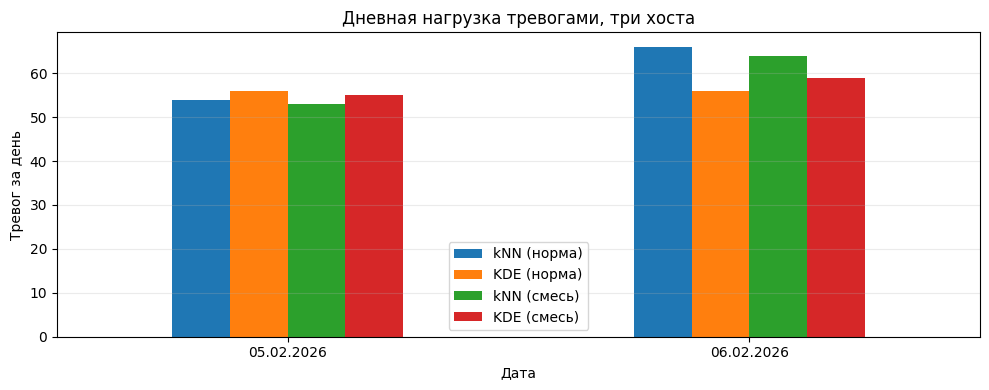

In [16]:
# Столбцы показывают число тревог для всех трёх хостов за день.
# Для подписи оси оставляем только календарную дату без времени 00:00:00.
daily_plot = daily_alerts.copy()
daily_plot.index = daily_plot.index.strftime('%d.%m.%Y')
ax = daily_plot.plot(kind='bar', figsize=(10, 4), rot=0)
ax.set_title('Дневная нагрузка тревогами, три хоста')
ax.set_xlabel('Дата')
ax.set_ylabel('Тревог за день')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

In [17]:
# Обе оценки устойчивости относятся к одним и тем же event_id.
# Устанавливаем event_id как индекс, чтобы явно сохранить соответствие строк.
stability_scores = monitoring_work.set_index('event_id')[
    ['score_knn_normal', 'score_knn_stability']
]
spearman_value = spearmanr(
    stability_scores['score_knn_normal'],
    stability_scores['score_knn_stability']
).statistic

# Стабильная сортировка сохраняет исходный порядок строк при равном score.
top_original = set(stability_scores.sort_values(
    'score_knn_normal', ascending=False, kind='stable'
).head(REVIEW_BUDGET).index)
top_stability = set(stability_scores.sort_values(
    'score_knn_stability', ascending=False, kind='stable'
).head(REVIEW_BUDGET).index)
jaccard_value = len(top_original & top_stability) / len(
    top_original | top_stability
)

print('Корреляция Спирмена:', round(spearman_value, 4))
print('Совпало окон в топ-40:', len(top_original & top_stability))
print('Индекс Жаккара топ-40:', round(jaccard_value, 4))

Корреляция Спирмена: 0.983
Совпало окон в топ-40: 38
Индекс Жаккара топ-40: 0.9048


### Вывод по заданию 3

Без доступа к истине на 8640 окнах мониторинга получено 120 тревог для kNN на норме, 112 для KDE на норме, 117 для kNN на смеси и 114 для KDE на смеси. Период длится ровно двое суток, поэтому суммарная нагрузка трёх хостов равна соответственно 60, 56, 58,5 и 57 тревогам в сутки. По дням kNN на норме вырос с 54 до 66 тревог, тогда как KDE на норме дал по 56 в оба дня; дневной график показывает эту разницу, которую скрывает среднее. Корреляция Спирмена между основным kNN и вариантом на 80 % истории равна 0,9830, а в топ-40 совпали 38 окон из 40 (Жаккар 0,9048). Это подтверждает похожесть ранжирования на данном наборе, но без разметки нельзя рассчитать число найденных атак, пропусков и ложных тревог. Устойчивое ранжирование может одинаково устойчиво выделять легитимный редкий трафик, поэтому устойчивость сама по себе не доказывает полезность для SOC.

## Задание 4. Проверка по подтверждённой истине

Время — 15 минут. Максимум — 4 балла.

1. Подключить проверочную истину к ранее оценённым окнам по event_id с проверкой one-to-one и сохранением соответствия оценок объектам
2. Для четырёх конфигураций определить число атакующих окон с тревогой и без неё, легитимных окон с тревогой и общее число тревог
3. Проверить равенство общего числа тревог сумме атакующих и легитимных срабатываний; сформировать таблицу обнаружения по scan, brute_force и exfiltration
4. Рассчитать число тревог на легитимных окнах в сутки и построить столбчатое сравнение обнаруженных окон по сценариям

**Результат:** Проверенное объединение истины, таблицы по окнам и сценариям, график и оценка ложной нагрузки.


In [18]:
# Только теперь присоединяем ранее сохранённую истину по event_id.
# validate='one_to_one' проверяет уникальность ключа с обеих сторон.
# sort=False сохраняет исходный порядок мониторинговых окон и их оценок.
verified = monitoring_work.merge(
    monitoring_truth, on='event_id', how='left',
    validate='one_to_one', sort=False
)
print('Рабочих и проверенных окон:', len(monitoring_work), len(verified))
print('Окон без подключённой истины:', int(verified['is_attack'].isna().sum()))

# Для каждой модели считаем четыре клетки матрицы ошибок.
# Равенство «все тревоги = атакующие + легитимные» проверяем явно.
window_rows = []
for name, flag_column in alert_columns.items():
    alarm = verified[flag_column]
    attack = verified['is_attack'] == 1
    tp = int((alarm & attack).sum())
    fn = int((~alarm & attack).sum())
    fp = int((alarm & ~attack).sum())
    tn = int((~alarm & ~attack).sum())
    total_alarms = int(alarm.sum())
    assert total_alarms == tp + fp
    window_rows.append({
        'Модель': name, 'Атака с тревогой (TP)': tp,
        'Атака без тревоги (FN)': fn,
        'Норма с тревогой (FP)': fp, 'Норма без тревоги (TN)': tn,
        'Всего тревог': total_alarms,
        'Ложных тревог в сутки': fp / observation_days
    })
window_table = pd.DataFrame(window_rows).set_index('Модель')
display(window_table)

# По сценариям считаем именно атакующие минутные окна.
attacks = verified.loc[verified['is_attack'] == 1].copy()
scenario_table = attacks.groupby('attack_type').size().to_frame('Всего окон')
for name, flag_column in alert_columns.items():
    scenario_table[name] = attacks.groupby('attack_type')[flag_column].sum()
display(scenario_table)

Рабочих и проверенных окон: 8640 8640
Окон без подключённой истины: 0


,Атака с тревогой (TP),Атака без тревоги (FN),Норма с тревогой (FP),Норма без тревоги (TN),Всего тревог,Ложных тревог в сутки
Модель,,,,,,
kNN (норма),44,70,76,8450,120,38.0
KDE (норма),47,67,65,8461,112,32.5
kNN (смесь),41,73,76,8450,117,38.0
KDE (смесь),45,69,69,8457,114,34.5


,Всего окон,kNN (норма),KDE (норма),kNN (смесь),KDE (смесь)
attack_type,,,,,
brute_force,38,18,20,16,18
exfiltration,38,4,5,4,5
scan,38,22,22,21,22


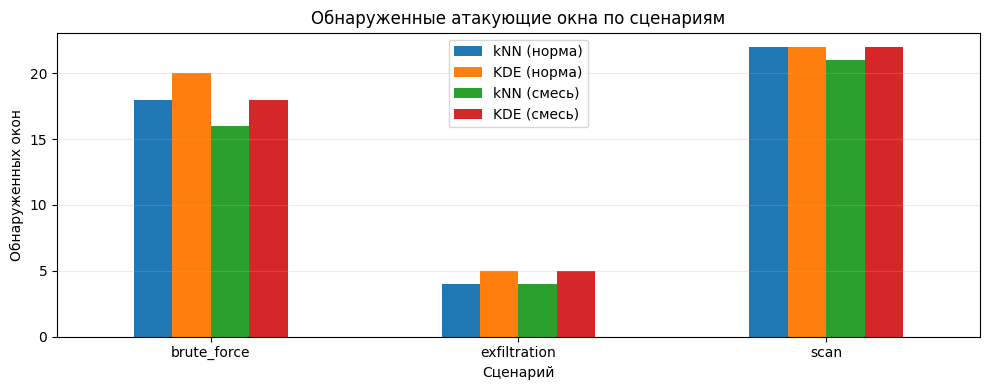

In [19]:
# Показываем, сколько атакующих окон каждого вида нашла модель.
ax = scenario_table[list(MODELS)].plot(kind='bar', figsize=(10, 4), rot=0)
ax.set_title('Обнаруженные атакующие окна по сценариям')
ax.set_xlabel('Сценарий')
ax.set_ylabel('Обнаруженных окон')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### Вывод по заданию 4

Истина присоединена к тем же 8640 окнам по уникальному `event_id`; непомеченных после объединения окон нет. Среди 114 атакующих окон kNN на норме обнаружил 44, KDE на норме — 47, kNN на смеси — 41, KDE на смеси — 45; соответственно 70, 67, 73 и 69 атакующих окон остались без тревоги. Легитимных окон с тревогой было 76, 65, 76 и 69, что даёт 38, 32,5, 38 и 34,5 ложных тревог в сутки. Для каждой модели общее число тревог равно сумме атакующих и легитимных срабатываний. KDE на норме обнаружил 22 из 38 окон `scan`, 20 из 38 `brute_force` и 5 из 38 `exfiltration`; слабое покрытие последнего сценария требует отдельного внимания. Число обнаруженных минутных окон не равно числу обнаруженных инцидентов: один инцидент может занимать несколько последовательных окон.

## Задание 5. Инциденты и практическая полезность для SOC

Время — 20 минут. Максимум — 6 балла.

1. Из всех атакующих окон сформировать каталог истинных инцидентов; считать инцидент обнаруженным при наличии хотя бы одной тревоги на его окнах
2. Для каждой конфигурации вычислить задержку от начала инцидента до первого window_end с тревогой; пропуски записать как NaN
3. Определить число обнаруженных и своевременно обнаруженных инцидентов с задержкой ≤ 3 минут; медиану считать только по обнаруженным, а долю своевременных — по всем известным инцидентам
4. Для KDE на норме объединить соседние тревоги одного хоста в заявки при промежутке ≤ 10 минут, не используя incident_id; сохранить связь заявок с исходными event_id
5. Для каждой конфигурации выбрать топ-40 по убыванию score и определить число и долю атакующих окон и число разных инцидентов в списке
6. Составить final_report и записку SOC из 5–7 предложений, сопоставив обнаружение, задержки, ложную нагрузку, заявки, бюджет и ограничения

**Результат:** Каталог и задержки инцидентов, заявки, результаты топ-40, итоговая таблица и обоснованный вывод SOC.


In [20]:
# Каталог истинных инцидентов строим только из атакующих окон.
# Окна одного инцидента объединены общей меткой incident_id.
incident_catalog = attacks.groupby('incident_id').agg(
    host_id=('host_id', 'first'),
    attack_type=('attack_type', 'first'),
    start=('timestamp', 'min'),
    end=('window_end', 'max'),
    attack_windows=('event_id', 'size')
)
print('Известных инцидентов:', len(incident_catalog))
display(incident_catalog)

# Время появления сигнала — конец первого окна с тревогой.
# Если по инциденту тревог нет, задержка остаётся NaN.
incident_delays = pd.DataFrame(index=incident_catalog.index)
for name, flag_column in alert_columns.items():
    first_alert_end = attacks.loc[attacks[flag_column]].groupby(
        'incident_id'
    )['window_end'].min()
    incident_delays[name] = (
        first_alert_end - incident_catalog['start']
    ).dt.total_seconds() / 60

print('Задержки от начала инцидента до первой тревоги, минуты:')
display(incident_delays)

# Медиану считаем только по найденным инцидентам: NaN пропускается.
# Долю своевременных считаем от ВСЕХ известных инцидентов.
incident_rows = []
for name in MODELS:
    delays = incident_delays[name]
    incident_rows.append({
        'Модель': name, 'Обнаружено инцидентов': int(delays.notna().sum()),
        'Пропущено инцидентов': int(delays.isna().sum()),
        'Своевременно ≤ 3 мин': int((delays <= DEADLINE_MINUTES).sum()),
        'Доля своевременных': (delays <= DEADLINE_MINUTES).sum()
                               / len(incident_catalog),
        'Медиана задержки, мин': delays.median()
    })
incident_summary = pd.DataFrame(incident_rows).set_index('Модель')
display(incident_summary)

Известных инцидентов: 18


,host_id,attack_type,start,end,attack_windows
incident_id,,,,,
INC-PZ-01,NODE-11,scan,2026-02-05 04:30:00,2026-02-05 04:34:00,4
INC-PZ-02,NODE-12,scan,2026-02-05 06:25:00,2026-02-05 06:31:00,6
INC-PZ-03,NODE-13,scan,2026-02-05 08:20:00,2026-02-05 08:29:00,9
INC-PZ-04,NODE-11,brute_force,2026-02-05 10:15:00,2026-02-05 10:19:00,4
INC-PZ-05,NODE-12,brute_force,2026-02-05 12:10:00,2026-02-05 12:16:00,6
INC-PZ-06,NODE-13,brute_force,2026-02-05 14:05:00,2026-02-05 14:14:00,9
INC-PZ-07,NODE-11,exfiltration,2026-02-05 16:00:00,2026-02-05 16:04:00,4
INC-PZ-08,NODE-12,exfiltration,2026-02-05 17:55:00,2026-02-05 18:01:00,6
INC-PZ-09,NODE-13,exfiltration,2026-02-05 19:50:00,2026-02-05 19:59:00,9


Задержки от начала инцидента до первой тревоги, минуты:


,kNN (норма),KDE (норма),kNN (смесь),KDE (смесь)
incident_id,,,,
INC-PZ-01,2.0,2.0,2.0,2.0
INC-PZ-02,4.0,4.0,4.0,4.0
INC-PZ-03,7.0,7.0,7.0,7.0
INC-PZ-04,3.0,3.0,3.0,3.0
INC-PZ-05,5.0,4.0,6.0,4.0
INC-PZ-06,8.0,7.0,8.0,7.0
INC-PZ-07,2.0,2.0,2.0,2.0
INC-PZ-08,NaN,NaN,NaN,NaN
INC-PZ-09,NaN,6.0,NaN,6.0


,Обнаружено инцидентов,Пропущено инцидентов,Своевременно ≤ 3 мин,Доля своевременных,"Медиана задержки, мин"
Модель,,,,,
kNN (норма),15,3,7,0.388889,4.0
KDE (норма),16,2,7,0.388889,4.0
kNN (смесь),15,3,7,0.388889,4.0
KDE (смесь),16,2,7,0.388889,4.0


In [21]:
# Заявки создаём только по тревогам KDE на норме.
# На этапе объединения используем хост, время и event_id — без incident_id.
kde_flag = alert_columns['KDE (норма)']
ticket_events = monitoring_work.loc[
    monitoring_work[kde_flag], ['event_id', 'host_id', 'window_end']
].copy()
ticket_events = ticket_events.rename(columns={'window_end': 'alert_time'})
ticket_events = ticket_events.sort_values(
    ['host_id', 'alert_time', 'event_id'], kind='stable'
).reset_index(drop=True)

# Новая заявка начинается у первой тревоги хоста или после разрыва >10 минут.
gap_minutes = ticket_events.groupby('host_id')[
    'alert_time'
].diff().dt.total_seconds() / 60
new_ticket = gap_minutes.isna() | (gap_minutes > JOIN_GAP_MINUTES)
ticket_number = new_ticket.groupby(ticket_events['host_id']).cumsum()
ticket_events['ticket_id'] = (
    ticket_events['host_id'] + '_' + ticket_number.astype(str)
)

# Сохраняем список исходных event_id для каждой заявки.
tickets = ticket_events.groupby('ticket_id', sort=False).agg(
    host_id=('host_id', 'first'),
    first_alert=('alert_time', 'min'),
    last_alert=('alert_time', 'max'),
    alert_windows=('event_id', 'size'),
    event_ids=('event_id', list)
)
print('Исходных тревог KDE (норма):', len(ticket_events))
print('Сформировано заявок:', len(tickets))
print('Сокращение числа отдельных задач:',
      round(1 - len(tickets) / len(ticket_events), 4))
display(tickets.head(10))

# Разметку подключаем только ПОСЛЕ формирования заявок, чтобы оценить их состав.
ticket_check = ticket_events[['ticket_id', 'event_id']].merge(
    monitoring_truth[['event_id', 'is_attack']],
    on='event_id', how='left', validate='one_to_one'
)
attack_tickets = int(ticket_check.groupby('ticket_id')['is_attack'].max().sum())
print('Заявок с хотя бы одним атакующим окном:', attack_tickets)

Исходных тревог KDE (норма): 112
Сформировано заявок: 47
Сокращение числа отдельных задач: 0.5804


,host_id,first_alert,last_alert,alert_windows,event_ids
ticket_id,,,,,
NODE-11_1,NODE-11,2026-02-05 01:31:00,2026-02-05 01:51:00,4,"[monitoring-00090-0, monitoring-00097-0, monit..."
NODE-11_2,NODE-11,2026-02-05 04:32:00,2026-02-05 04:34:00,3,"[monitoring-00271-0, monitoring-00272-0, monit..."
NODE-11_3,NODE-11,2026-02-05 05:11:00,2026-02-05 05:11:00,1,[monitoring-00310-0]
NODE-11_4,NODE-11,2026-02-05 10:18:00,2026-02-05 10:19:00,2,"[monitoring-00617-0, monitoring-00618-0]"
NODE-11_5,NODE-11,2026-02-05 11:05:00,2026-02-05 11:05:00,1,[monitoring-00664-0]
NODE-11_6,NODE-11,2026-02-05 16:02:00,2026-02-05 16:02:00,1,[monitoring-00961-0]
NODE-11_7,NODE-11,2026-02-05 22:32:00,2026-02-05 22:32:00,1,[monitoring-01351-0]
NODE-11_8,NODE-11,2026-02-06 01:28:00,2026-02-06 01:34:00,2,"[monitoring-01527-0, monitoring-01533-0]"
NODE-11_9,NODE-11,2026-02-06 04:32:00,2026-02-06 04:34:00,3,"[monitoring-01711-0, monitoring-01712-0, monit..."


Заявок с хотя бы одним атакующим окном: 16


In [22]:
# Топ-40 выбираем ОДИН раз на весь двухсуточный пакет.
# kind='stable' сохраняет порядок исходных строк при равном score.
review_rows = []
for name, score_column in MODELS.items():
    top = verified.sort_values(
        score_column, ascending=False, kind='stable'
    ).head(REVIEW_BUDGET)
    attack_windows_in_top = int(top['is_attack'].sum())
    incident_count_in_top = top.loc[
        top['is_attack'] == 1, 'incident_id'
    ].nunique()
    review_rows.append({
        'Модель': name,
        'Атакующих окон в топ-40': attack_windows_in_top,
        'Доля атакующих окон в топ-40': attack_windows_in_top / REVIEW_BUDGET,
        'Разных инцидентов в топ-40': incident_count_in_top
    })
review_summary = pd.DataFrame(review_rows).set_index('Модель')
display(review_summary)

# Итог соединяет метрики разных уровней: окно, инцидент и бюджет проверки.
final_report = window_table.join(incident_summary).join(review_summary)
final_report['Заявок'] = np.nan
final_report.loc['KDE (норма)', 'Заявок'] = len(tickets)
print('Итоговый отчёт:')
display(final_report.round(4))

,Атакующих окон в топ-40,Доля атакующих окон в топ-40,Разных инцидентов в топ-40
Модель,,,
kNN (норма),30,0.750,12
KDE (норма),34,0.850,12
kNN (смесь),31,0.775,11
KDE (смесь),34,0.850,12


Итоговый отчёт:


,Атака с тревогой (TP),Атака без тревоги (FN),Норма с тревогой (FP),Норма без тревоги (TN),Всего тревог,Ложных тревог в сутки,Обнаружено инцидентов,Пропущено инцидентов,Своевременно ≤ 3 мин,Доля своевременных,"Медиана задержки, мин",Атакующих окон в топ-40,Доля атакующих окон в топ-40,Разных инцидентов в топ-40,Заявок
Модель,,,,,,,,,,,,,,,
kNN (норма),44,70,76,8450,120,38.0,15,3,7,0.3889,4.0,30,0.750,12,NaN
KDE (норма),47,67,65,8461,112,32.5,16,2,7,0.3889,4.0,34,0.850,12,47.0
kNN (смесь),41,73,76,8450,117,38.0,15,3,7,0.3889,4.0,31,0.775,11,NaN
KDE (смесь),45,69,69,8457,114,34.5,16,2,7,0.3889,4.0,34,0.850,12,NaN


### Вывод по заданию 5

Из 114 атакующих окон составлен каталог 18 истинных инцидентов: kNN в обоих режимах обнаружил по 15 инцидентов, KDE в обоих режимах — по 16. Для KDE на норме пропущены `INC-PZ-08` и `INC-PZ-17`, а для kNN на норме — `INC-PZ-08`, `INC-PZ-09` и `INC-PZ-18`; пропуски отражены как `NaN` и не входят в медиану задержки. У всех четырёх конфигураций медиана задержки среди обнаруженных инцидентов равна 4 минутам, а своевременно обнаружены лишь 7 из 18 инцидентов (38,89 %) при сроке 3 минуты. Из 112 исходных тревог KDE на норме правило соседних тревог одного хоста сформировало 47 заявок, причём 16 заявок содержат хотя бы одно атакующее окно; заявка не является подтверждённым инцидентом. В едином топ-40 KDE на норме и KDE на смеси содержат по 34 атакующих окна (85 %) и по 12 разных инцидентов, kNN на норме — 30 окон (75 %) и 12 инцидентов, kNN на смеси — 31 окно (77,5 %) и 11 инцидентов. Для решения SOC нужно сопоставлять качество по окнам, число инцидентов, задержку, ложную нагрузку и полезность ограниченного бюджета, не смешивая эти единицы учёта.

## Записка SOC

За 5–6 февраля 2026 года проанализированы 8640 минутных окон трёх хостов с заранее установленными `α=0,01`, строгим `score > T`, сроком оповещения 3 минуты и бюджетом 40 окон на весь период. Пороги, взятые только из `calibration`, составили для kNN и KDE на норме 0,8313 и 8,2082, а для вариантов на смеси 0,7981 и 7,7485. На проверочном мониторинге KDE на норме обнаружил 47 из 114 атакующих окон при 65 ложных тревогах (32,5 в сутки), kNN на норме — 44 при 76; оба варианта на смеси обнаружили 41 и 45 окон при 76 и 69 ложных тревогах. На уровне 18 инцидентов KDE обнаружил 16, пропустив `INC-PZ-08` и `INC-PZ-17`, тогда как kNN обнаружил 15; у всех четырёх вариантов только 7 инцидентов замечены не позднее 3 минут, а медиана задержки среди найденных равна 4 минутам. Объединение 112 тревог KDE на норме по соседним сообщениям одного хоста с промежутком не больше 10 минут дало 47 заявок, из них 16 содержали атакующие окна. В топ-40 KDE на норме оказалось 34 атакующих окна и 12 разных инцидентов против 30 окон и 12 инцидентов у kNN на норме: KDE дал более высокую долю атакующих окон при том же охвате инцидентов. Для практического применения следует проверить причины пропущенной эксфильтрации, высокую долю тревог на легитимном `backup` и сдвиг нормы; связанные минутные окна, синтетический фон и фиксированные пороги ограничивают перенос этих чисел на реальную сеть.